# 02 · Delivery KPIs and operational patterns

Use the verified order mart to measure reliability and locate the late-order burden across purchase cohorts and states. The following notebook connects these delivery outcomes to reviews.

[Previous](01_data_quality_and_sql.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](03_reviews_and_sensitivity.ipynb)

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/olist_analytics").is_dir(), (
    "Open from the project root or notebooks directory."
)
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"


DB = ROOT / "data/processed/olist.sqlite3"
DB_URI = DB.as_uri() + "?mode=ro"

## What share of eligible deliveries missed the promised date?

Use the validated conditional aggregate and explicitly reconcile its denominator and saved export.

In [2]:
kpis_sql = (ROOT / "sql/03_kpis.sql").read_text()
print(kpis_sql)
with closing(sqlite3.connect(DB_URI, uri=True)) as connection:
    kpis = pd.read_sql_query(kpis_sql, connection)
saved_kpis = pd.read_csv(TABLES / "kpis.csv")
pd.testing.assert_frame_equal(kpis, saved_kpis, check_dtype=False)
display(kpis[["total_orders", "eligible_delivered_orders", "late_orders", "late_rate"]])

-- Each KPI exports its denominator. Non-delivered and invalid-date orders are not "on time".
SELECT COUNT(*) AS total_orders,
 SUM(order_status = 'delivered') AS delivered_status_orders,
 SUM(delivery_eligible) AS eligible_delivered_orders,
 SUM(CASE WHEN delivery_eligible = 1 THEN is_late ELSE 0 END) AS late_orders,
 SUM(delivery_eligible) - SUM(CASE WHEN delivery_eligible = 1 THEN is_late ELSE 0 END) AS on_time_orders,
 1.0 * SUM(is_late) / NULLIF(SUM(delivery_eligible), 0) AS late_rate,
 AVG(delivery_days) AS mean_delivery_days,
 AVG(CASE WHEN delivery_eligible = 1 THEN review_score END) AS mean_review_score_eligible,
 SUM(delivery_eligible = 1 AND review_score IS NOT NULL) AS eligible_reviewed_orders
FROM order_fact;



,total_orders,eligible_delivered_orders,late_orders,late_rate
0,99441,96470,6534,0.067731


6,534 of 96,470 eligible orders arrived late (6.77%). Comparing time and geography requires keeping the number of orders at risk of being counted late alongside the rate.

## Does lateness vary across purchase cohorts?

Use the verified monthly view. Its rate panel applies the minimum of 200 eligible deliveries and its volume panel retains every cohort.

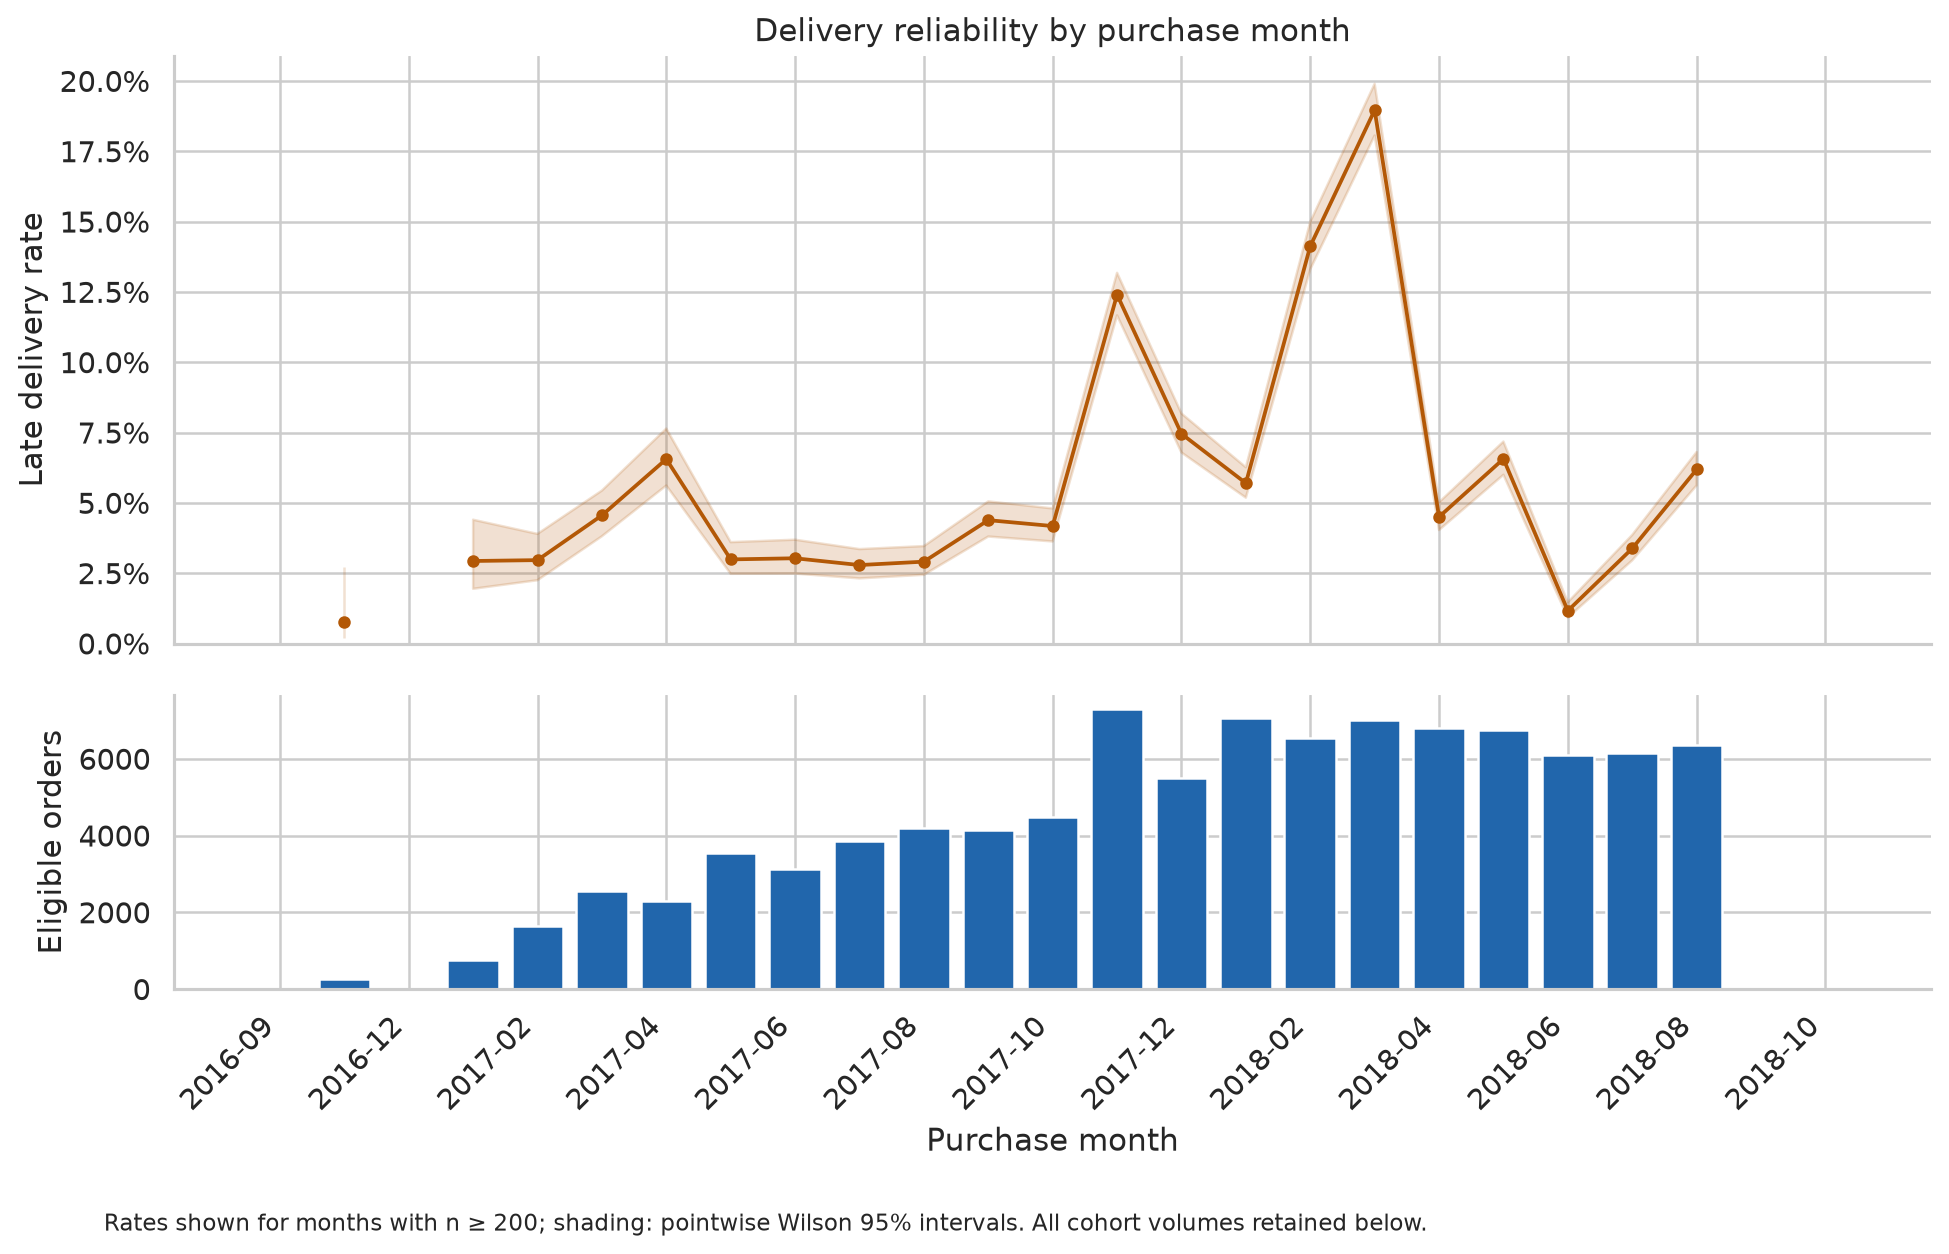

In [3]:
display(Image(filename=str(REPORTS / "figures/01_monthly_reliability.png"), width=900))

Read spikes with their cohort size and interval. The historical sample and partial edge periods limit comparisons across months.

## Which states have the highest counts and highest rates?

Use the same eligibility rule in every state. The rate screen requires at least 200 eligible orders. The chart highlights the 12 highest-volume states.

SELECT customer_state, COUNT(*) AS total_orders,
 SUM(delivery_eligible) AS eligible_orders, SUM(is_late) AS late_orders,
 1.0 * SUM(is_late) / NULLIF(SUM(delivery_eligible), 0) AS late_rate,
 AVG(delivery_days) AS mean_delivery_days,
 AVG(CASE WHEN delivery_eligible = 1 THEN review_score END) AS mean_review_score
FROM order_fact GROUP BY customer_state ORDER BY eligible_orders DESC;



,customer_state,eligible_orders,late_orders,late_rate
0,SP,40494,1820,0.044945
1,RJ,12350,1495,0.121053
2,MG,11354,519,0.045711


,customer_state,eligible_orders,late_orders,late_rate
19,AL,397,85,0.214106
14,MA,717,125,0.174338
20,SE,335,51,0.152239


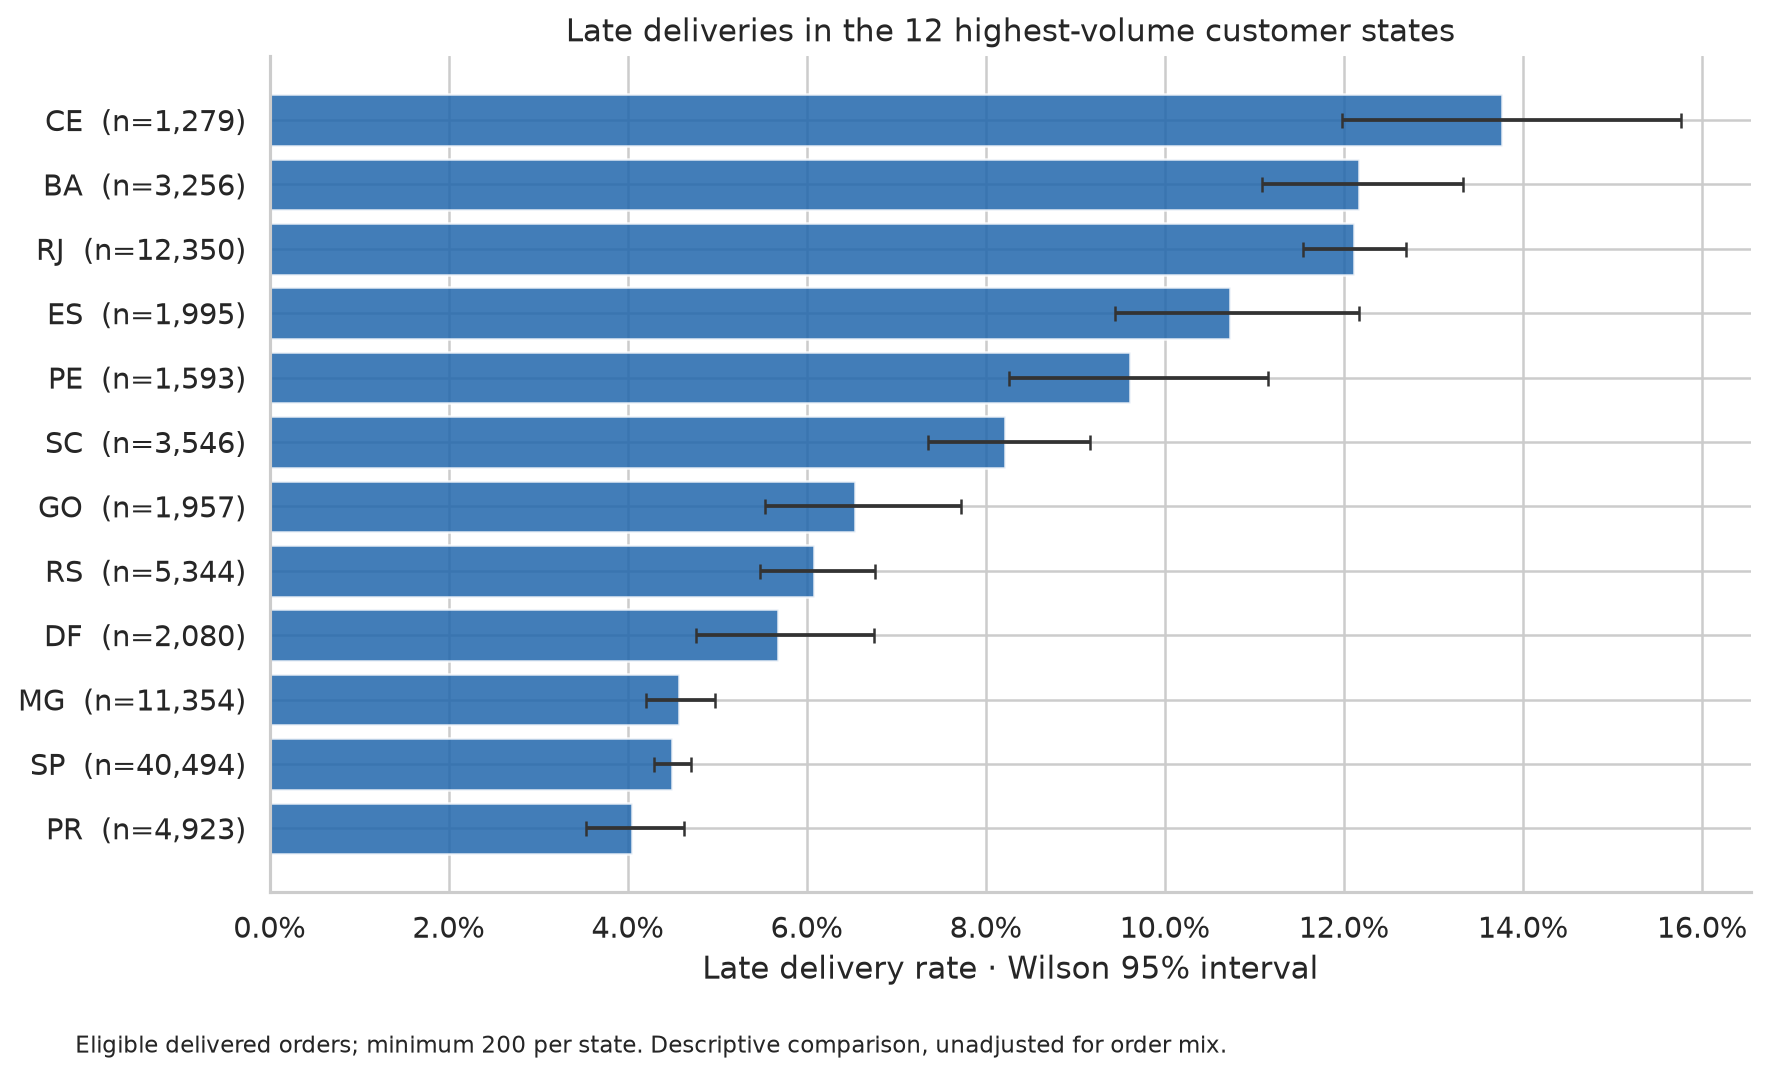

In [4]:
states_sql = (ROOT / "sql/05_states.sql").read_text()
print(states_sql)
with closing(sqlite3.connect(DB_URI, uri=True)) as connection:
    states = pd.read_sql_query(states_sql, connection)
columns = ["customer_state", "eligible_orders", "late_orders", "late_rate"]
display(states.nlargest(3, "late_orders")[columns])
display(states.loc[states["eligible_orders"].ge(200)].nlargest(3, "late_rate")[columns])
assert np.isclose(states["late_orders"].sum(), kpis.at[0, "late_orders"])
display(Image(filename=str(REPORTS / "figures/02_state_reliability.png"), width=900))

SP accounts for the highest late-order volume. AL leads the rate screen. Those are distinct operational priorities, and the chart’s volume selection may omit states with high rates.

## How do elapsed delivery times compare?

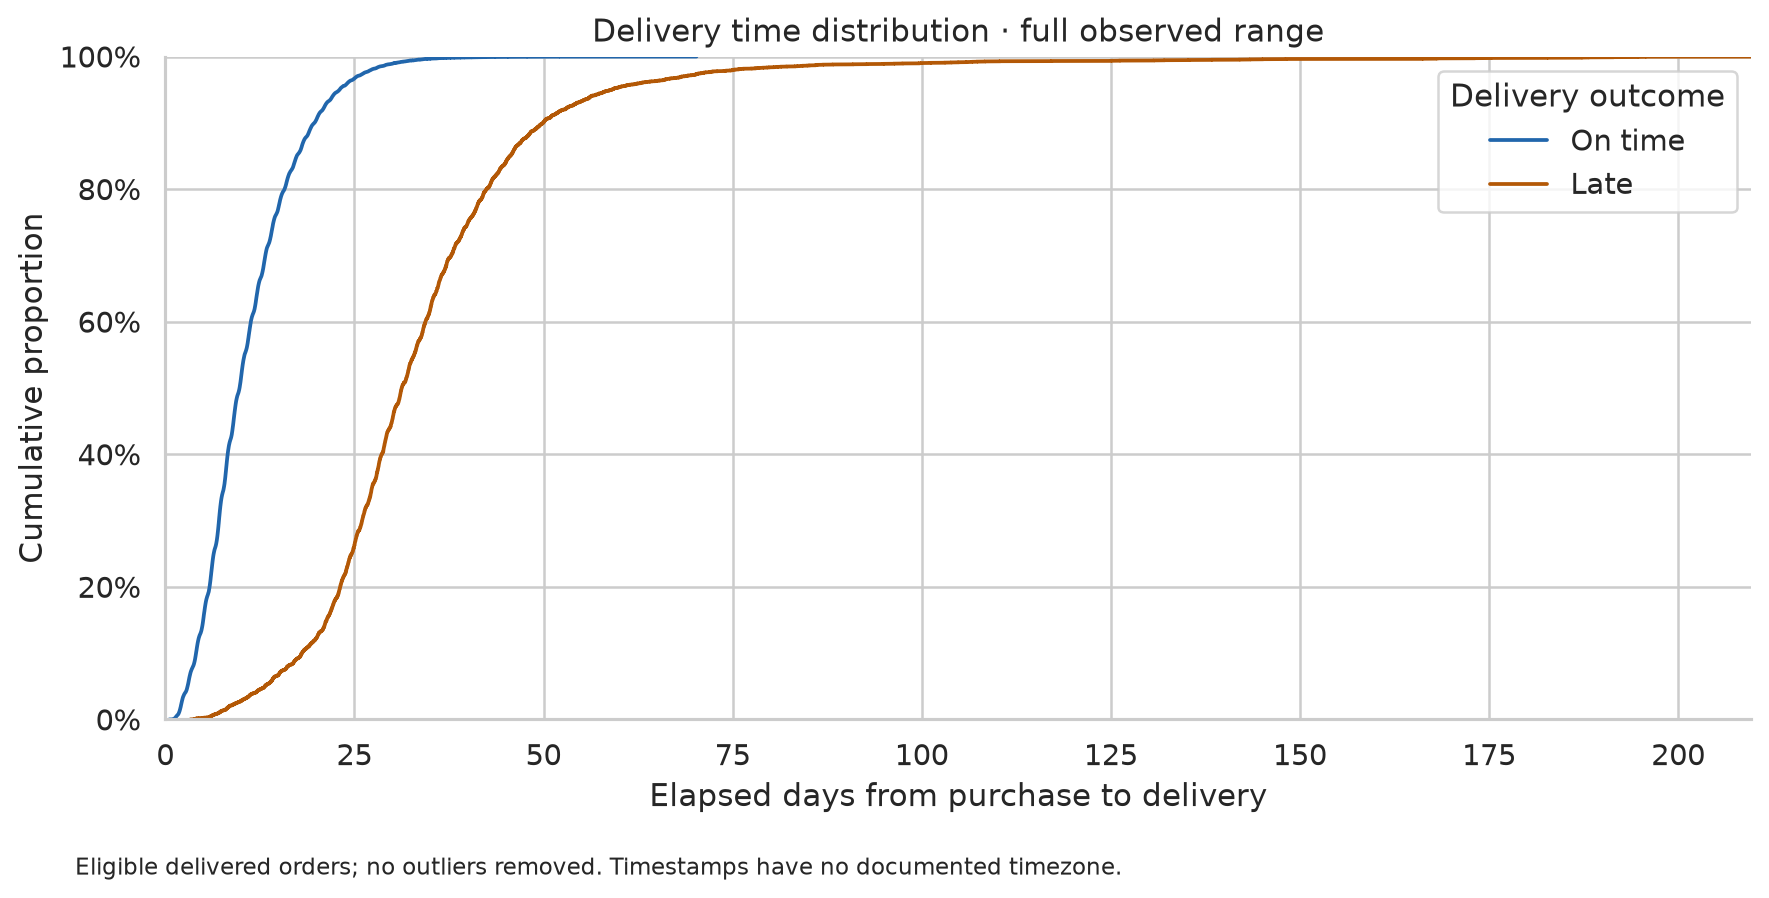

In [5]:
display(Image(filename=str(REPORTS / "figures/05_delivery_time_ecdf.png"), width=900))

The empirical cumulative distribution shows that the late group generally takes longer to receive orders. The calendar deadline depends on the promised date, so elapsed days alone cannot define lateness. Next, check whether customer feedback tells the same story.

[Previous](01_data_quality_and_sql.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](03_reviews_and_sensitivity.ipynb)